# Monte Carlo Risk Modeling of a Heterogeneous Life Insurance Portfolio
### A one-year study using Polish mortality data

An insurance portfolio consists of many individual risks, but the insurer is concerned with their combined payout. Here, six groups have different mortality probabilities and death benefits. The model uses the 2025 Polish life table for mortality; policy counts and benefits are hypothetical.

Four experiments examine the annual payout distribution, the effects of scale and concentration, Monte Carlo estimation error, and the normal approximation to high losses.

Run the notebook from the repository root with the Python 3.12 environment defined in `uv.lock`. It reads the local CSV and overwrites the files in `outputs/` on each run.


In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm, chi2, binom
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
assert (ROOT / 'data/mortality_2025.csv').exists(), 'Open/run from the repository root.'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.20})
BLUE, ORANGE, GREEN = '#24558A', '#D46B35', '#23876D'

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, bbox_inches='tight')
    display(Image(filename=str(OUT / name)))
    plt.close(fig)

print({'python': platform.python_version(), 'numpy': np.__version__,
       'pandas': pd.__version__, 'scipy': scipy.__version__})


{'python': '3.12.15', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0'}


## Data and portfolio

Mortality probabilities come from Statistics Poland (GUS), [*Trwanie życia w 2025 r.*, Table A](https://stat.gov.pl/obszary-tematyczne/ludnosc/trwanie-zycia/trwanie-zycia-w-2025-r-%2C2%2C20.html). We use the `Ogółem mężczyźni` worksheet for ages 30, 45 and 60. The extracted CSV and source workbook are included in `data/`; extraction details are in `data/README.md`.

Here, $q_x$ is the probability of dying between ages $x$ and $x+1$, conditional on reaching age $x$. The policy counts and benefits are hypothetical.


In [2]:
mortality = pd.read_csv(ROOT / 'data/mortality_2025.csv')
assert mortality['age'].is_unique
assert mortality['sex'].eq('male').all()
assert mortality['q_x'].between(0, 1).all()
assert mortality['age'].tolist() == [30, 45, 60]
np.testing.assert_allclose(mortality['q_x'], [0.00117, 0.00346, 0.01313], rtol=0, atol=1e-15)
display(
    mortality.style.format({'q_x': '{:.5f}'})
    .hide(axis='index')
)

# The only baseline parameter block. Counts and benefits are synthetic.
portfolio = pd.DataFrame({
    'age': [30, 30, 45, 45, 60, 60],
    'n': [1000, 2000, 1500, 1000, 2500, 2000],
    'K_PLN': [50000, 100000, 100000, 200000, 50000, 200000],
})
portfolio = portfolio.merge(mortality[['age', 'q_x']], on='age', validate='many_to_one', sort=False)
n = portfolio['n'].to_numpy()
q = portfolio['q_x'].to_numpy()
K = portfolio['K_PLN'].to_numpy(dtype=float)
N = int(n.sum())
M_MAIN = 100_000
SEED = 20261019
H = 50_000  # Greatest common lattice unit of all baseline benefits (PLN).
assert np.all(K % H == 0)
display(portfolio.style.format({
    'n': '{:,.0f}',
    'K_PLN': '{:,.0f}',
    'q_x': '{:.5f}'
}).hide(axis='index'))


age,q_x,sex,source_cell
30,0.00117,male,B37
45,0.00346,male,B52
60,0.01313,male,B67


age,n,K_PLN,q_x
30,"1,000","50,000",0.00117
30,"2,000","100,000",0.00117
45,"1,500","100,000",0.00346
45,"1,000","200,000",0.00346
60,"2,500","50,000",0.01313
60,"2,000","200,000",0.01313


## Model and simulation functions

Let $X_{gi}$ indicate whether person $i$ in group $g$ dies during the year. Assuming independent deaths,

$$X_{gi}\sim\mathrm{Bernoulli}(q_g),\qquad D_g=\sum_{i=1}^{n_g}X_{gi}\sim\mathrm{Binomial}(n_g,q_g).$$

With a fixed benefit $K_g$ per death, the total payout is

$$S=\sum_gK_gD_g,\qquad
\mu=E[S]=\sum_gK_gn_gq_g,\qquad
v=\operatorname{Var}(S)=\sum_gK_g^2n_gq_g(1-q_g).$$

The standard deviation is $\sigma=\sqrt v$. Because the groups differ in mortality and benefits, the aggregate payout is not binomial. Its distribution can be estimated by Monte Carlo or computed by convolution.

`simulate()` draws an $M\times G$ matrix of group death counts rather than an $M\times N$ matrix of individual outcomes. Separate seeded streams are used for each experiment and repetition. We consistently calculate strict exceedances $P(S>B)$ and empirical quantiles using the inverse-CDF definition (`method='inverted_cdf'`). Sample variances use `ddof=1`.


In [3]:
def validate(n, q, K):
    assert n.ndim == q.ndim == K.ndim == 1 and n.shape == q.shape == K.shape
    assert len(n) > 0 and np.all(np.isfinite(n))
    assert np.all(n >= 0) and np.all(n == np.floor(n)) and n.sum() > 0
    assert np.all(np.isfinite(q)) and np.all((0 <= q) & (q <= 1))
    assert np.all(np.isfinite(K)) and np.all(K > 0)

def moments(n, q, K):
    validate(n, q, K)
    mu = float(np.sum(K * n * q))
    var = float(np.sum(K**2 * n * q * (1 - q)))
    return mu, var, np.sqrt(var)

def simulate(n, q, K, M, experiment, scenario=0, repetition=0):
    validate(n, q, K)
    assert isinstance(M, (int, np.integer)) and M > 0
    rng = np.random.default_rng(np.random.SeedSequence([SEED, experiment, scenario, repetition]))
    deaths = rng.binomial(np.asarray(n, dtype=np.int64), q, size=(M, len(n)))
    return deaths @ K

def empirical_quantile(samples, p):
    return np.quantile(samples, p, method='inverted_cdf')

def tail_summary(samples, budget):
    # Wilson 95% interval: remains informative even for zero observed exceedances.
    trials = len(samples)
    hits = int(np.count_nonzero(samples > budget))
    phat = hits / trials
    z = norm.ppf(0.975)
    den = 1 + z*z/trials
    center = (phat + z*z/(2*trials)) / den
    half = z*np.sqrt(phat*(1-phat)/trials + z*z/(4*trials**2)) / den
    return phat, max(0., center-half), min(1., center+half)

def gaussian_tail(mu, sigma, budget, h):
    # Largest possible lattice payout <= B is h*floor(B/h).
    boundary = h*np.floor(np.asarray(budget)/h) + h/2
    return norm.sf((boundary - mu)/sigma)

def gaussian_quantile(mu, sigma, p, h, maximum):
    # Smallest lattice s with Phi((s+h/2-mu)/sigma) >= p.
    return np.clip(h*np.ceil((mu + sigma*norm.ppf(p))/h - 0.5), 0, maximum)

mu, var, sigma = moments(n, q, K)
BUDGET = H * np.ceil((mu + 2*sigma)/H)  # Defined from theory, not fitted to simulated losses.
print(f'E[S] = {mu:,.2f} PLN; Var(S) = {var:,.2f} PLN²; SD = {sigma:,.2f} PLN')
print(f'Average pure premium = {mu/N:,.3f} PLN/person; common budget = {BUDGET:,.0f} PLN')


E[S] = 8,396,750.00 PLN; Var(S) = 1,333,529,029,125.00 PLN²; SD = 1,154,785.27 PLN
Average pure premium = 839.675 PLN/person; common budget = 10,750,000 PLN


## I. Annual payout distribution

We simulate 100,000 independent annual portfolio outcomes and calculate the mean, variance, quantiles and probability of exceeding a fixed budget.

The Monte Carlo standard error of the mean is $SE(\bar S)=\sigma/\sqrt M$. For the sample variance, we use

$$SE(s^2)=\sqrt{\frac{\mu_4-\frac{M-3}{M-1}v^2}{M}},\qquad
\mu_4=3v^2+\sum_g n_gK_g^4q_g(1-q_g)\left[1-6q_g(1-q_g)\right].$$

The numerical checks allow discrepancies of up to six standard errors between simulated and analytic moments.


metric,MC,analytic
mean_PLN,"8,398,839","8,396,750"
variance_PLN2,"1,338,974,741,826","1,333,529,029,125"
sd_PLN,"1,157,141","1,154,785"
median_PLN,"8,350,000",—
q95_PLN,"10,350,000",—
q99_PLN,"11,200,000",—
P(S>B),2.436%,—


Mean discrepancy: 0.572 SE; variance discrepancy: 0.907 SE
P(S > 10,750,000) = 0.02436; Wilson 95% MC interval [0.02342, 0.02533]


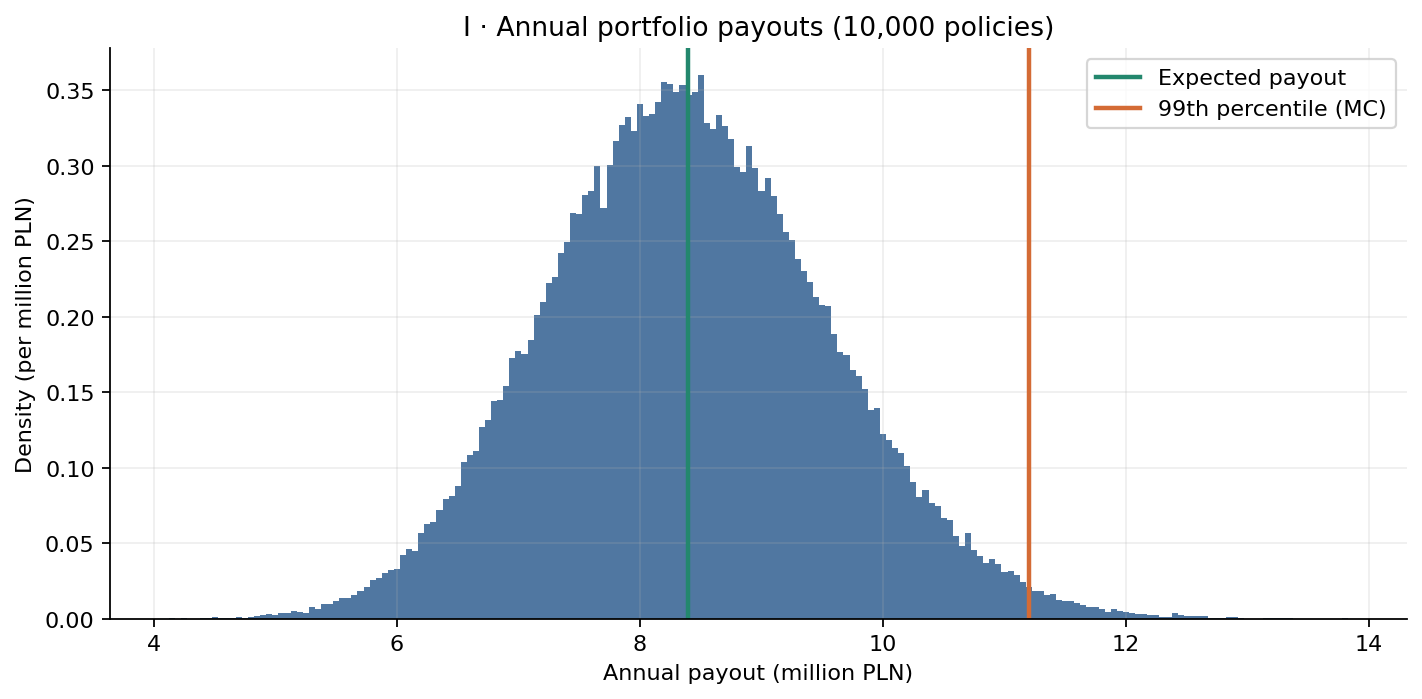

In [4]:
S = simulate(n, q, K, M_MAIN, experiment=1)
p_tail, p_lo, p_hi = tail_summary(S, BUDGET)
kappa4 = np.sum(n*K**4*q*(1-q)*(1-6*q*(1-q)))
mu4 = 3*var**2 + kappa4
se_mean = sigma/np.sqrt(M_MAIN)
se_var = np.sqrt((mu4 - (M_MAIN-3)/(M_MAIN-1)*var**2)/M_MAIN)
mean_z = (S.mean()-mu)/se_mean
variance_z = (S.var(ddof=1)-var)/se_var
assert abs(mean_z) < 6
assert abs(variance_z) < 6
assert np.all(S % H == 0)
experiment1 = pd.DataFrame({
    'metric': ['mean_PLN', 'variance_PLN2', 'sd_PLN', 'median_PLN', 'q95_PLN', 'q99_PLN', 'P(S>B)'],
    'MC': [S.mean(), S.var(ddof=1), S.std(ddof=1), empirical_quantile(S, .5),
           empirical_quantile(S, .95), empirical_quantile(S, .99), p_tail],
    'analytic': [mu, var, sigma, np.nan, np.nan, np.nan, np.nan],
})
display(
    experiment1.style
    .format({'MC': '{:,.0f}', 'analytic': '{:,.0f}'}, na_rep='—')
    .format('{:.3%}', subset=(experiment1.index[-1:], ['MC', 'analytic']), na_rep='—')
    .hide(axis='index')
)
print(f'Mean discrepancy: {mean_z:.3f} SE; variance discrepancy: {variance_z:.3f} SE')
print(f'P(S > {BUDGET:,.0f}) = {p_tail:.5f}; Wilson 95% MC interval [{p_lo:.5f}, {p_hi:.5f}]')
fig, ax = plt.subplots(figsize=(9, 4.5))
edges = np.arange(S.min()-H/2, S.max()+H, H)
ax.hist(S/1e6, bins=edges/1e6, density=True, color=BLUE, alpha=.8)
ax.axvline(mu/1e6, color=GREEN, label='Expected payout', lw=2)
ax.axvline(empirical_quantile(S, .99)/1e6, color=ORANGE, label='99th percentile (MC)', lw=2)
ax.set(xlabel='Annual payout (million PLN)', ylabel='Density (per million PLN)',
       title='I · Annual portfolio payouts (10,000 policies)')
ax.legend()
save_figure(fig, '01_loss_distribution.png')


## II. Diversification and concentration

### A. Varying portfolio size

Scale every group count by $c$, leaving $q_g$ and $K_g$ unchanged. The analytic moments then satisfy

$$\mu(c)=c\mu,\qquad v(c)=cv,\qquad \sigma(c)=\sqrt c\,\sigma,\qquad CV(c)=\frac{CV(1)}{\sqrt c}.$$

Thus the coefficient of variation falls as $N^{-1/2}$ at fixed portfolio composition and with independent deaths. The standard deviation in PLN, however, increases as $\sqrt N$. The experiment compares the theoretical relationship with simulated values.


scale,N,mean_PLN,sd_PLN,CV_theory,CV_MC
0.1,"1,000","839,675","365,175",43.490%,43.474%
0.5,"5,000","4,198,375","816,556",19.449%,19.409%
1.0,"10,000","8,396,750","1,154,785",13.753%,13.756%
2.0,"20,000","16,793,500","1,633,113",9.725%,9.700%
5.0,"50,000","41,983,750","2,582,178",6.150%,6.146%


Simulated log-log slope: -0.5002; theoretical slope: -0.5


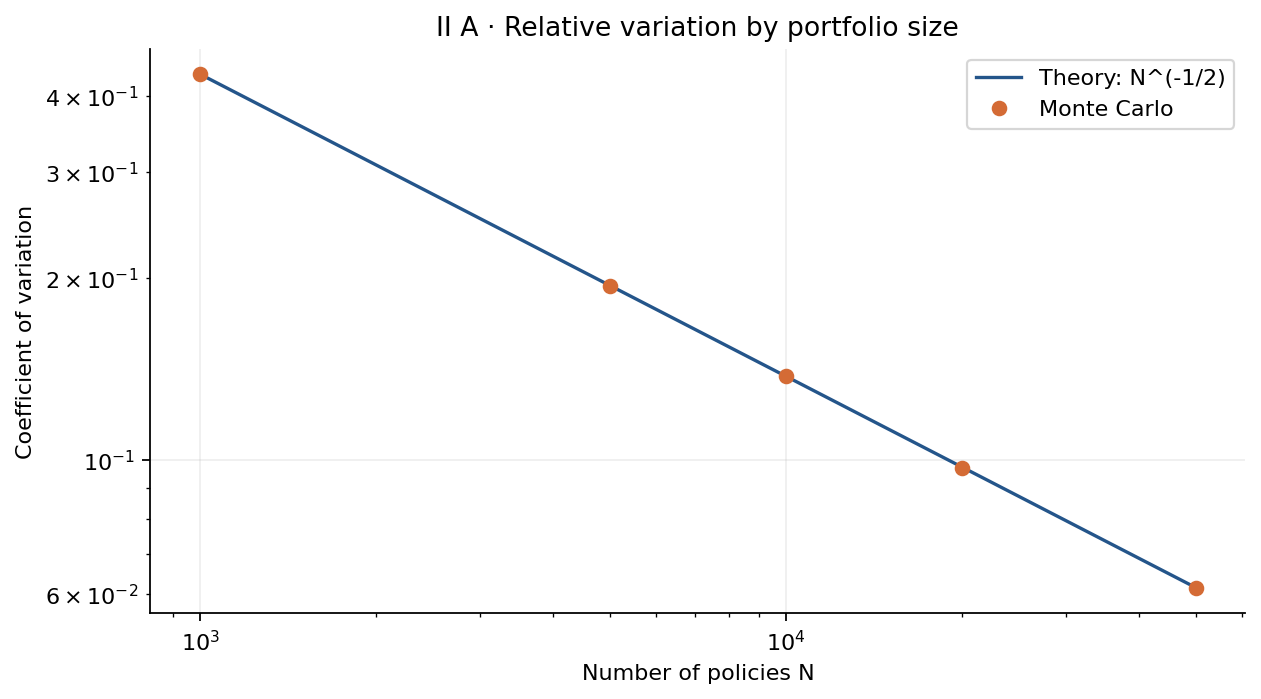

In [5]:
scale_rows = []
for j, c in enumerate([.1, .5, 1., 2., 5.]):
    assert np.all(n*c == np.floor(n*c))
    nc = (n*c).astype(int)
    muc, vc, sdc = moments(nc, q, K)
    sample = simulate(nc, q, K, M_MAIN, 2, j)
    scale_rows.append({'scale': c, 'N': int(nc.sum()), 'mean_PLN': muc, 'sd_PLN': sdc,
                       'CV_theory': sdc/muc, 'CV_MC': sample.std(ddof=1)/sample.mean()})
scale_table = pd.DataFrame(scale_rows)
np.testing.assert_allclose(scale_table.CV_theory, sigma/mu/np.sqrt(scale_table.scale))
scale_slope = np.polyfit(np.log(scale_table.N), np.log(scale_table.CV_MC), 1)[0]
display(scale_table.style.format({
    'scale': '{:.1f}',
    'N': '{:,.0f}',
    'mean_PLN': '{:,.0f}',
    'sd_PLN': '{:,.0f}',
    'CV_theory': '{:.3%}',
    'CV_MC': '{:.3%}'
}).hide(axis='index'))
print(f'Simulated log-log slope: {scale_slope:.4f}; theoretical slope: -0.5')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.loglog(scale_table.N, scale_table.CV_theory, color=BLUE, label='Theory: N^(-1/2)')
ax.loglog(scale_table.N, scale_table.CV_MC, 'o', color=ORANGE, label='Monte Carlo')
ax.set(xlabel='Number of policies N', ylabel='Coefficient of variation', title='II A · Relative variation by portfolio size')
ax.legend()
save_figure(fig, '02_diversification.png')


### B. Concentrating the same expected payout

The comparison portfolio has **one tenth as many policies** in each group and a **tenfold benefit** per policy: $n'_g=n_g/10$, $K'_g=10K_g$, $q'_g=q_g$. This preserves the expected payout and the total nominal sum insured, while increasing variance by a factor of ten.

Each portfolio is simulated independently 100,000 times and compared against the same budget.


In [6]:
n_concentrated = n//10
K_concentrated = K*10
mu_c, var_c, sd_c = moments(n_concentrated, q, K_concentrated)
np.testing.assert_allclose(mu_c, mu)
np.testing.assert_allclose(var_c, 10*var)
concentration_rows = []
for j, (label, nn, kk) in enumerate([
    ('Baseline', n, K), ('Concentrated', n_concentrated, K_concentrated)
]):
    loss = simulate(nn, q, kk, M_MAIN, 2, 10+j)
    mm, vv, ss = moments(nn, q, kk)
    pp, lo, hi = tail_summary(loss, BUDGET)
    concentration_rows.append({'portfolio': label, 'N': int(nn.sum()), 'mean_PLN': mm,
        'variance_PLN2': vv, 'q99_MC_PLN': empirical_quantile(loss, .99),
        'budget_PLN': BUDGET, 'P(S>B)': pp, 'MC95_low': lo, 'MC95_high': hi})
concentration_table = pd.DataFrame(concentration_rows)
display(concentration_table.style.format({
    'N': '{:,.0f}',
    'mean_PLN': '{:,.0f}',
    'variance_PLN2': '{:,.0f}',
    'q99_MC_PLN': '{:,.0f}',
    'budget_PLN': '{:,.0f}',
    'P(S>B)': '{:.3%}',
    'MC95_low': '{:.3%}',
    'MC95_high': '{:.3%}'
}).hide(axis='index'))


portfolio,N,mean_PLN,variance_PLN2,q99_MC_PLN,budget_PLN,P(S>B),MC95_low,MC95_high
Baseline,"10,000","8,396,750","1,333,529,029,125","11,250,000","10,750,000",2.293%,2.202%,2.388%
Concentrated,"1,000","8,396,750","13,335,290,291,250","18,000,000","10,750,000",24.528%,24.262%,24.796%


## III. Convergence of Monte Carlo estimates

For $M=100$, $1{,}000$, $10{,}000$ and $100{,}000$, estimate the mean 30 times using independent random streams. The standard deviation of annual payouts is $\sigma$; the standard error of the estimated mean is $\sigma/\sqrt M$. We compare this prediction with the observed spread across repetitions.

The error bars describe uncertainty in the observed standard deviation across 30 repetitions, based on a chi-square approximation for approximately normal sample means. The empirical slope need not be exactly $-1/2$. High quantiles and rare-event probabilities generally need more simulations than a mean estimate.


M,SD_of_means_PLN,SE_theory_PLN,SD95_low,SD95_high,RMSE_PLN
100,"129,315","115,479","102,987","173,840","128,033"
"1,000","35,723","36,518","28,450","48,023","36,267"
"10,000","10,652","11,548","8,483","14,320","10,722"
"100,000","3,155","3,652","2,513","4,241","3,263"


Observed SD log-log slope: -0.5363


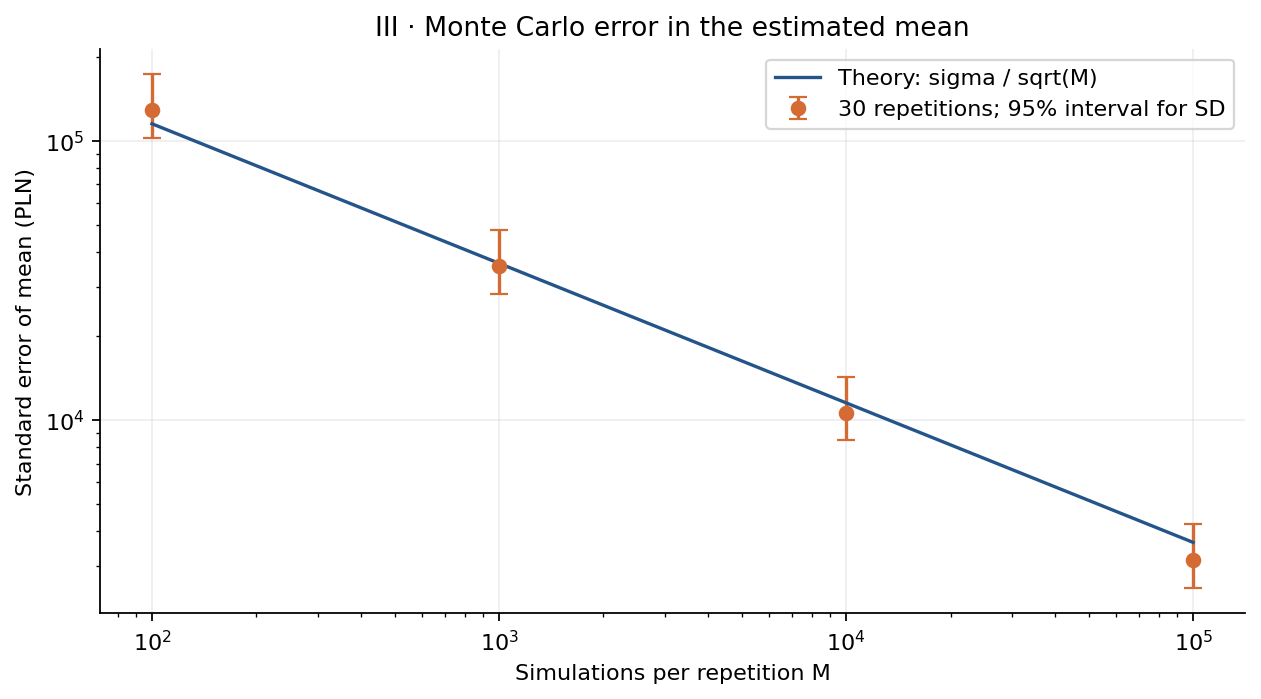

In [7]:
REPETITIONS = 30
convergence_rows = []
for j, M in enumerate([100, 1000, 10000, 100000]):
    means = np.array([simulate(n, q, K, M, 3, j, r).mean() for r in range(REPETITIONS)])
    observed = means.std(ddof=1)
    df = REPETITIONS-1
    lo = observed*np.sqrt(df/chi2.ppf(.975, df))
    hi = observed*np.sqrt(df/chi2.ppf(.025, df))
    convergence_rows.append({'M': M, 'SD_of_means_PLN': observed,
        'SE_theory_PLN': sigma/np.sqrt(M), 'SD95_low': lo, 'SD95_high': hi,
        'RMSE_PLN': np.sqrt(np.mean((means-mu)**2))})
convergence_table = pd.DataFrame(convergence_rows)
convergence_slope = np.polyfit(np.log(convergence_table.M), np.log(convergence_table.SD_of_means_PLN), 1)[0]
display(convergence_table.style.format({
    'M': '{:,.0f}',
    'SD_of_means_PLN': '{:,.0f}',
    'SE_theory_PLN': '{:,.0f}',
    'SD95_low': '{:,.0f}',
    'SD95_high': '{:,.0f}',
    'RMSE_PLN': '{:,.0f}'
}).hide(axis='index'))
print(f'Observed SD log-log slope: {convergence_slope:.4f}')
fig, ax = plt.subplots(figsize=(8, 4.5))
y = convergence_table.SD_of_means_PLN.to_numpy()
ax.errorbar(convergence_table.M, y, yerr=[y-convergence_table.SD95_low, convergence_table.SD95_high-y],
            fmt='o', color=ORANGE, capsize=4, label='30 repetitions; 95% interval for SD')
ax.plot(convergence_table.M, convergence_table.SE_theory_PLN, color=BLUE, label='Theory: sigma / sqrt(M)')
ax.set(xscale='log', yscale='log', xlabel='Simulations per repetition M',
       ylabel='Standard error of mean (PLN)', title='III · Monte Carlo error in the estimated mean')
ax.legend()
save_figure(fig, '03_mc_convergence.png')


## IV. Normal approximation and the upper tail

For three proportional portfolio sizes ($N=100$, $1{,}000$, $10{,}000$), approximate aggregate payouts by $\mathcal N(\mu,\sigma^2)$. The central limit theorem suggests improving agreement near the centre as the portfolio grows. We test how well the approximation captures the upper tail.

**Continuity correction.** The payouts lie on a grid with step $h=50{,}000$ PLN. When the budget $B$ lies on this grid, $S>B$ begins at $B+h$, so the corresponding normal boundary is $B+h/2$. For a budget between grid points the boundary becomes $h\lfloor B/h\rfloor+h/2$.

The lattice-adjusted normal quantile is the smallest grid point whose continuity-corrected normal CDF reaches $p$:

$$Q_p^{N,h}=h\left\lceil\frac{\mu+\sigma\Phi^{-1}(p)}h-\frac12\right\rceil.$$

The result is clipped to the possible payout range. We report both continuous and lattice-adjusted normal quantiles; the grid must be recalculated if benefit amounts change.

We set each comparison budget from the analytic moments, $B=h\lceil(\mu+2.5\sigma)/h\rceil$, before sampling. The tables report exceedance probabilities with 95% Wilson intervals, normal estimates with and without continuity correction, and the 95th and 99th percentiles.


N,budget_PLN,skewness,P_MC,MC95_low,MC95_high,P_normal_raw,P_normal_CC,MC_minus_normal_CC,relative_shortfall,normal_outside_MC95
100,"400,000",1.564,1.449%,1.377%,1.525%,0.310%,0.157%,+1.292%,89.1%,Yes
"1,000","1,800,000",0.495,0.988%,0.929%,1.051%,0.427%,0.349%,+0.639%,64.7%,Yes
"10,000","11,300,000",0.156,0.790%,0.737%,0.847%,0.597%,0.561%,+0.229%,29.0%,Yes


N,p,Q_MC_PLN,Q_MC95_low,Q_MC95_high,Q_normal_continuous_PLN,Q_normal_lattice_PLN,MC_minus_normal_PLN
100,95%,"300,000","300,000","300,000","273,913","250,000","+50,000"
100,99%,"450,000","450,000","450,000","352,611","350,000","+100,000"
"1,000",95%,"1,500,000","1,500,000","1,500,000","1,440,335","1,450,000","+50,000"
"1,000",99%,"1,800,000","1,800,000","1,850,000","1,689,199","1,700,000","+100,000"
"10,000",95%,"10,350,000","10,300,000","10,350,000","10,296,203","10,300,000","+50,000"
"10,000",99%,"11,200,000","11,150,000","11,250,000","11,083,182","11,100,000","+100,000"


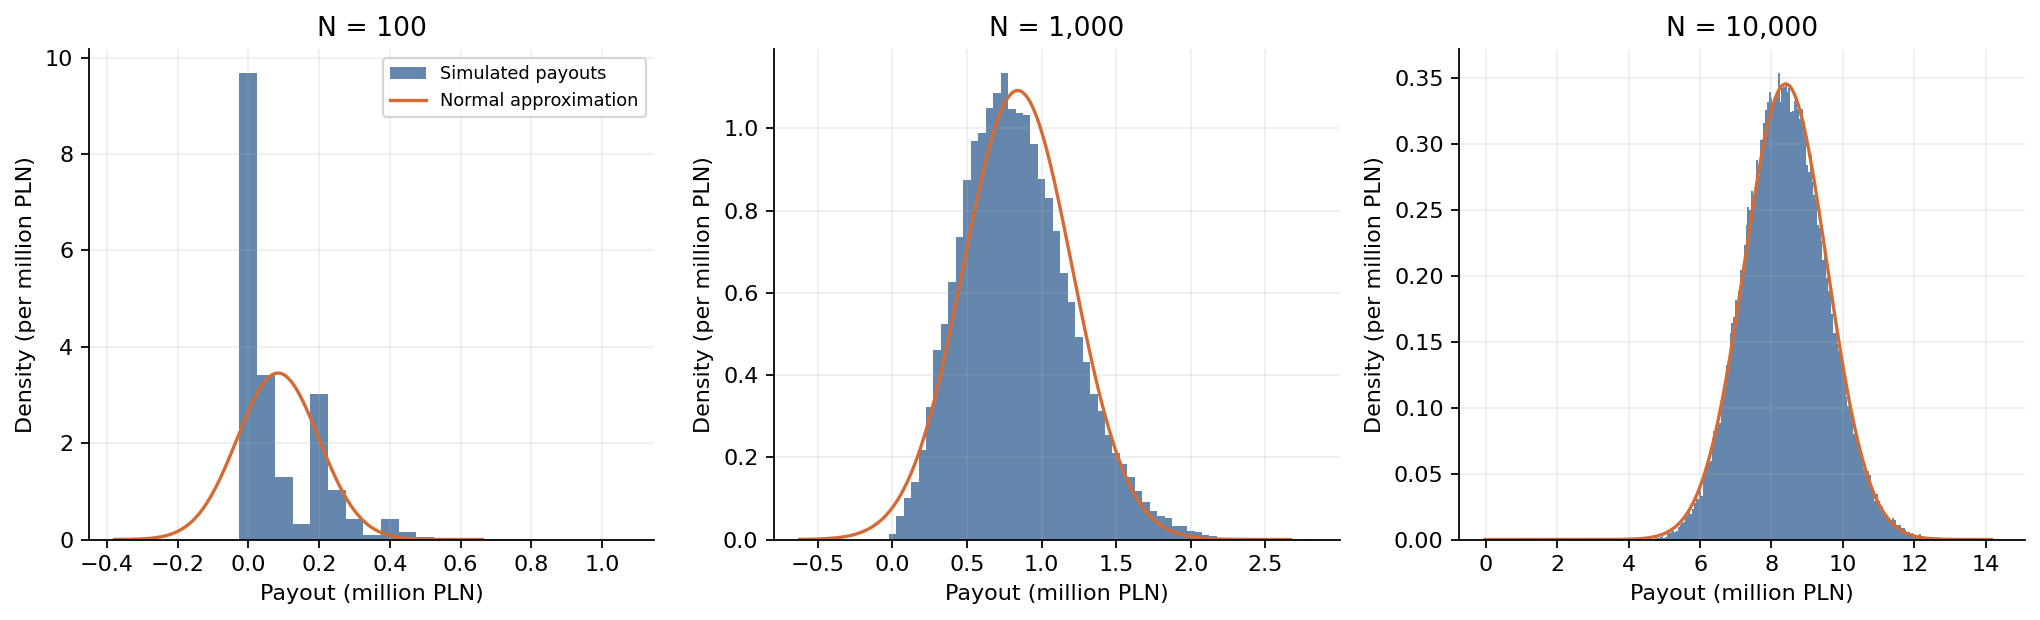

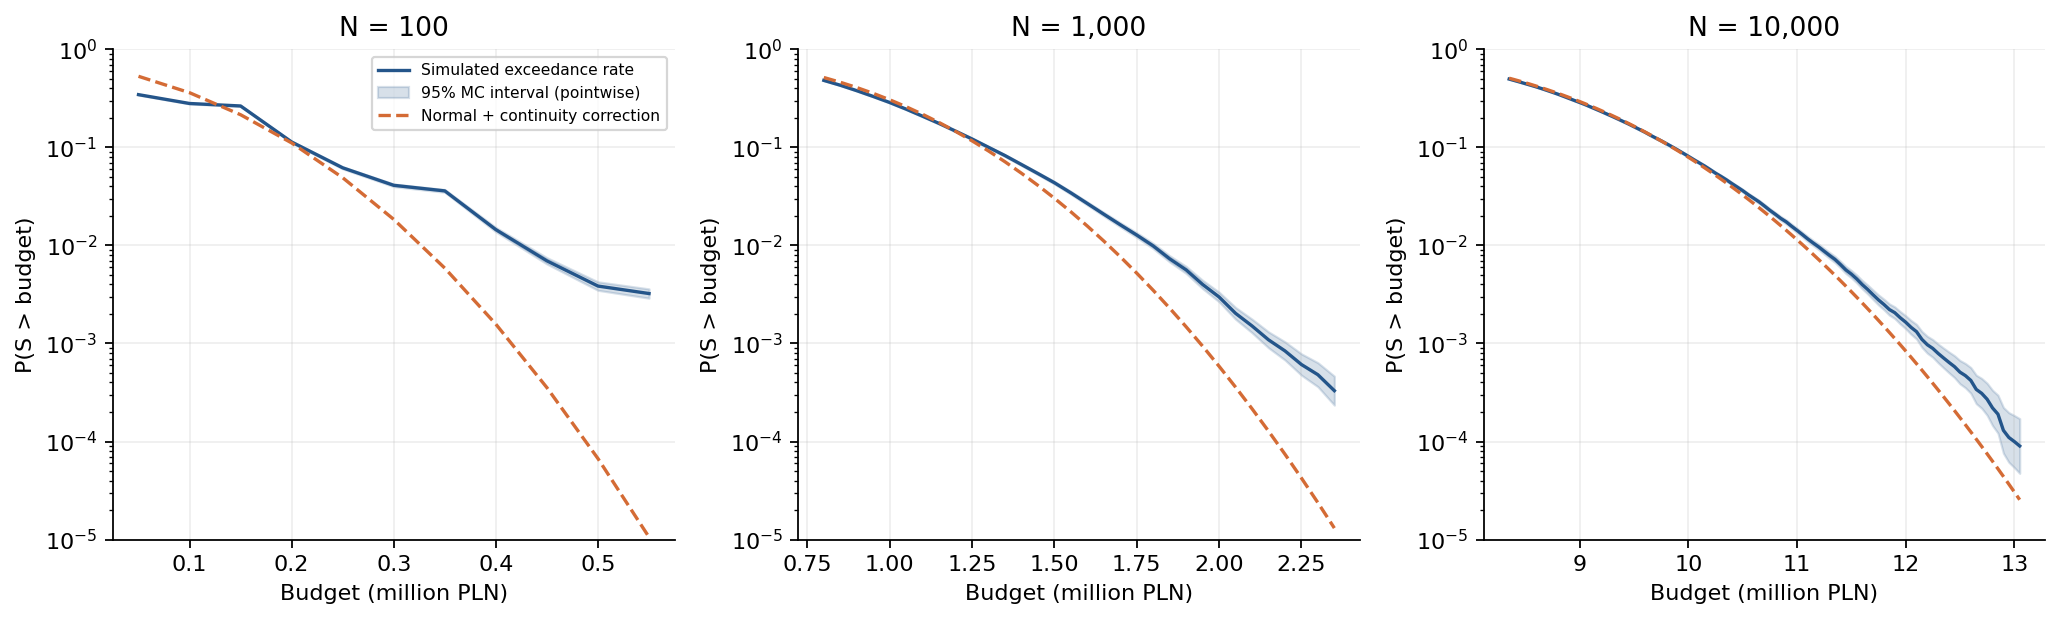

In [8]:
clt_rows, quantile_rows, clt_samples = [], [], []
for j, c in enumerate([.01, .1, 1.]):
    assert np.all(n*c == np.floor(n*c))
    nn = (n*c).astype(int)
    mm, vv, ss = moments(nn, q, K)
    loss = simulate(nn, q, K, M_MAIN, 4, j)
    budget = H*np.ceil((mm + 2.5*ss)/H)
    p, lo, hi = tail_summary(loss, budget)
    pg = float(gaussian_tail(mm, ss, budget, H))
    skew = float(np.sum(nn*K**3*q*(1-q)*(1-2*q))/ss**3)
    clt_rows.append({'N': int(nn.sum()), 'budget_PLN': budget, 'skewness': skew,
        'P_MC': p, 'MC95_low': lo, 'MC95_high': hi,
        'P_normal_raw': norm.sf((budget-mm)/ss), 'P_normal_CC': pg,
        'MC_minus_normal_CC': p-pg, 'relative_shortfall': (p-pg)/p if p else np.nan,
        'normal_outside_MC95': not lo <= pg <= hi})
    for level in [.95, .99]:
        # Conservative distribution-free order-statistic interval for the population quantile.
        # Ties on a lattice make it conservative; no assumption of a smooth density.
        ordered = np.sort(loss)
        lower_rank = max(1, int(binom.ppf(.025, M_MAIN, level)))
        upper_rank = min(M_MAIN, int(binom.ppf(.975, M_MAIN, level))+1)
        mcq = float(empirical_quantile(loss, level))
        nq = float(gaussian_quantile(mm, ss, level, H, np.sum(nn*K)))
        quantile_rows.append({'N': int(nn.sum()), 'p': level, 'Q_MC_PLN': mcq,
            'Q_MC95_low': ordered[lower_rank-1], 'Q_MC95_high': ordered[upper_rank-1],
            'Q_normal_continuous_PLN': mm+ss*norm.ppf(level), 'Q_normal_lattice_PLN': nq,
            'MC_minus_normal_PLN': mcq-nq})
    clt_samples.append((int(nn.sum()), mm, ss, loss))
clt_table = pd.DataFrame(clt_rows)
quantile_table = pd.DataFrame(quantile_rows)
display(clt_table.style.format({
    'N': '{:,.0f}',
    'budget_PLN': '{:,.0f}',
    'skewness': '{:.3f}',
    'P_MC': '{:.3%}',
    'MC95_low': '{:.3%}',
    'MC95_high': '{:.3%}',
    'P_normal_raw': '{:.3%}',
    'P_normal_CC': '{:.3%}',
    'MC_minus_normal_CC': '{:+.3%}',
    'relative_shortfall': '{:.1%}',
    'normal_outside_MC95': lambda flag: 'Yes' if flag else 'No'
}).hide(axis='index'))
display(quantile_table.style.format({
    'N': '{:,.0f}',
    'p': '{:.0%}',
    'Q_MC_PLN': '{:,.0f}',
    'Q_MC95_low': '{:,.0f}',
    'Q_MC95_high': '{:,.0f}',
    'Q_normal_continuous_PLN': '{:,.0f}',
    'Q_normal_lattice_PLN': '{:,.0f}',
    'MC_minus_normal_PLN': '{:+,.0f}'
}).hide(axis='index'))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (size, mm, ss, loss) in zip(axes, clt_samples):
    edges = np.arange(-H/2, loss.max()+H, H)
    ax.hist(loss/1e6, bins=edges/1e6, density=True, alpha=.7, color=BLUE, label='Simulated payouts')
    x = np.linspace(min(-H/2, mm-4*ss), mm+5*ss, 500)
    ax.plot(x/1e6, norm.pdf(x, mm, ss)*1e6, color=ORANGE, label='Normal approximation')
    ax.set(title=f'N = {size:,}', xlabel='Payout (million PLN)', ylabel='Density (per million PLN)')
axes[0].legend(fontsize=8)
save_figure(fig, '04_gaussian_distributions.png')

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (size, mm, ss, loss) in zip(axes, clt_samples):
    thresholds = np.arange(max(0, H*np.floor(mm/H)), H*np.ceil((mm+4*ss)/H)+H, H)
    tails = np.array([tail_summary(loss, b) for b in thresholds])
    ax.plot(thresholds/1e6, tails[:, 0], color=BLUE, label='Simulated exceedance rate')
    ax.fill_between(thresholds/1e6, tails[:, 1], tails[:, 2], color=BLUE, alpha=.18, label='95% MC interval (pointwise)')
    ax.plot(thresholds/1e6, gaussian_tail(mm, ss, thresholds, H), color=ORANGE, linestyle='--', label='Normal + continuity correction')
    ax.set(yscale='log', ylim=(1e-5, 1), title=f'N = {size:,}',
           xlabel='Budget (million PLN)', ylabel='P(S > budget)')
axes[0].legend(fontsize=7)
save_figure(fig, '05_gaussian_tails.png')


## Numerical checks

The final checks cover input validity, moment formulas, seeded replay, discrete quantiles and strict tail thresholds. For the moments, a two-person Bernoulli example is enumerated directly, independently of the simulation. Edge cases with $q=0$ and $q=1$ test deterministic outcomes. The other checks verify the payout-grid correction and the memory size of the group-count matrix.


In [9]:
# Independent enumeration for two distinct Bernoulli benefits.
toy_outcomes = np.array([0., 10., 30., 40.])
toy_prob = np.array([.8*.7, .2*.7, .8*.3, .2*.3])
toy_mu = np.dot(toy_outcomes, toy_prob)
toy_var = np.dot((toy_outcomes-toy_mu)**2, toy_prob)
np.testing.assert_allclose(moments(np.array([1, 1]), np.array([.2, .3]), np.array([10., 30.]))[:2],
                           [toy_mu, toy_var])
np.testing.assert_array_equal(simulate(n, q, K, 50, 90), simulate(n, q, K, 50, 90))
np.testing.assert_array_equal(simulate(np.array([2, 3]), np.array([0., 1.]), np.array([10., 20.]), 10, 91),
                              np.full(10, 60.))
assert empirical_quantile(np.array([0., 50000.]), .5) == 0
assert tail_summary(np.array([0., 50000., 100000.]), 50000)[0] == 1/3
np.testing.assert_allclose(gaussian_tail(mu, sigma, BUDGET, H), norm.sf((BUDGET+H/2-mu)/sigma))
np.testing.assert_allclose(gaussian_tail(mu, sigma, BUDGET+H*.2, H), gaussian_tail(mu, sigma, BUDGET, H))
for level in [.95, .99]:
    gq = gaussian_quantile(mu, sigma, level, H, np.sum(n*K))
    assert norm.cdf((gq+H/2-mu)/sigma) >= level
    assert norm.cdf((gq-H/2-mu)/sigma) < level
# Largest deaths matrix: 100000 x 6 x 8 bytes = 4.8 MB (decimal).
assert M_MAIN*len(n)*np.dtype(np.int64).itemsize == 4_800_000
print('All numerical and reproducibility checks passed.')


All numerical and reproducibility checks passed.


## Summary of results

The following figures are calculated from the simulated and analytic results.


In [10]:
small = clt_table.iloc[0]
large = clt_table.iloc[-1]
q99_base = empirical_quantile(S, .99)
q99_conc = concentration_table.iloc[1].q99_MC_PLN
summary_text = f"""
- **I. Annual payouts:** analytic mean **{mu:,.0f} PLN**, simulated mean **{S.mean():,.0f} PLN**, 99th percentile **{q99_base:,.0f} PLN**. The probability of exceeding **{BUDGET:,.0f} PLN** is **{p_tail:.3%}** (95% Wilson interval: **{p_lo:.3%}–{p_hi:.3%}**).
- **II. Diversification:** fitted CV scaling exponent **{scale_slope:.3f}** (theory: **−0.5**). Concentrating benefits increases variance **{var_c/var:.0f}-fold** at the same mean; the simulated 99th percentile is **{q99_conc:,.0f} PLN**.
- **III. Convergence:** fitted scaling exponent for the SD of estimated means **{convergence_slope:.3f}**. At **M = 100,000**, the theoretical standard error is **{se_mean:,.0f} PLN**.
- **IV. Normal approximation:** for **N = 100**, tail probability **{small.P_MC:.3%}** (Monte Carlo) versus **{small.P_normal_CC:.3%}** (normal with continuity correction); for **N = 10,000**, **{large.P_MC:.3%}** versus **{large.P_normal_CC:.3%}**.
"""
display(Markdown(summary_text))
# Save numerical results.
for name, table in [('experiment1', experiment1), ('scale', scale_table),
                    ('concentration', concentration_table), ('convergence', convergence_table),
                    ('gaussian_tails', clt_table), ('gaussian_quantiles', quantile_table)]:
    table.to_csv(OUT / f'{name}.csv', index=False)
summary = {'mean_theory_PLN': mu, 'variance_theory_PLN2': var, 'sd_theory_PLN': sigma,
    'pure_premium_PLN': mu/N, 'mean_MC_PLN': float(S.mean()), 'q99_MC_PLN': float(q99_base),
    'budget_PLN': float(BUDGET), 'tail_MC': p_tail, 'tail_MC95': [p_lo, p_hi],
    'mean_error_SE': float(mean_z), 'variance_error_SE': float(variance_z),
    'scale_slope_MC': float(scale_slope), 'convergence_slope_MC': float(convergence_slope),
    'SE_mean_M100000_PLN': float(se_mean), 'seed': SEED, 'M_main': M_MAIN}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2)+'\n')



- **I. Annual payouts:** analytic mean **8,396,750 PLN**, simulated mean **8,398,839 PLN**, 99th percentile **11,200,000 PLN**. The probability of exceeding **10,750,000 PLN** is **2.436%** (95% Wilson interval: **2.342%–2.533%**).
- **II. Diversification:** fitted CV scaling exponent **-0.500** (theory: **−0.5**). Concentrating benefits increases variance **10-fold** at the same mean; the simulated 99th percentile is **18,000,000 PLN**.
- **III. Convergence:** fitted scaling exponent for the SD of estimated means **-0.536**. At **M = 100,000**, the theoretical standard error is **3,652 PLN**.
- **IV. Normal approximation:** for **N = 100**, tail probability **1.449%** (Monte Carlo) versus **0.157%** (normal with continuity correction); for **N = 10,000**, **0.790%** versus **0.561%**.


581

### Discussion

Relative payout fluctuations decrease as the portfolio grows. Concentrating the same total sum insured in fewer, larger policies has the opposite effect: the expected payout stays constant, while the variance increases tenfold and the simulated 99th percentile rises substantially.

In all three portfolio sizes tested, the normal approximation underestimates upper-tail probabilities and 99th percentiles. The discrepancy is largest for the smallest portfolio and becomes smaller as the number of policies increases.

The calculations use mortality rates for the general male population and assume independent deaths. Mortality specific to insured lives, common shocks and changes over time could affect the distribution of payouts. The analysis covers one year and excludes expenses, discounting and reinsurance.
